# Дополнительное задание: нейронная сеть, кросс-валидация, подбор гиперпараметров и TensorBoard
**Датасет:** Dry Bean (13611 зёрен фасоли, 7 сортов, 9 признаков формы из лабораторной работы 2), **задача:** многоклассовая классификация.

**Цель** – освоить пайплайн обучения нейронной сети на TensorFlow: кросс-валидация, подбор гиперпараметров и мониторинг обучения.

**Что делает ноутбук (по пунктам задания):**
1. загрузка и первичный анализ данных, выводы о балансе классов и необходимых преобразованиях;
2. baseline – логистическая регрессия, accuracy на отложенной выборке;
3. 5-кратная стратифицированная кросс-валидация;
4. Grid Search с кросс-валидацией: 3 скорости обучения × 3 архитектуры сети (45 обучений);
5. мониторинг в TensorBoard: loss и accuracy на каждом фолде;
6. сравнение конфигураций по accuracy, loss, времени обучения и устойчивости между фолдами;
7. финальная оценка лучшей конфигурации против baseline, анализ влияния гиперпараметров, переобучения и недообучения.

*Запуск.* Ячейки выполняются сверху вниз; весь расчёт занимает около 25 минут на одном ядре процессора, результаты обучений кэшируются в папке `cache_extra`, повторный запуск быстрый. Файл `Dry_Bean_Dataset.xlsx` должен лежать рядом с ноутбуком. Числа в тексте получены при `random_state = 44`; при повторном обучении сетей они могут слегка отличаться (TensorFlow не гарантирует побитовой воспроизводимости).

In [1]:
import os, time, gc, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss
from scipy.stats import binomtest
import tensorflow as tf
import keras

warnings.filterwarnings("ignore")      # фильтр ставится после импортов, чтобы библиотеки его не сбросили
sns.set_theme(style="whitegrid")

FAST = False                           # True - только отладка на малой выборке
RS = 44                                # random_state как в лабораторной работе 2
DATA_PATH, SHEET, TARGET = "Dry_Bean_Dataset.xlsx", "Dry_Beans_Dataset", "Class"
OUT = "out_extra_fast" if FAST else "out_extra"; CACHE = "cache_extra_fast" if FAST else "cache_extra"; LOGS = "logs_extra_fast" if FAST else "logs_extra"
for d in (OUT, CACHE): os.makedirs(d, exist_ok=True)
np.random.seed(RS); keras.utils.set_random_seed(RS)

def cached(name, fn):
    """Долгие расчёты сохраняются на диск: повторный запуск ячейки их не пересчитывает."""
    path = f"{CACHE}/{name}.joblib"
    if os.path.exists(path): return joblib.load(path)
    res = fn(); joblib.dump(res, path); return res

## 1. Загрузка и подготовка данных

Размер: (13611, 17)
Пропусков всего: 0 | полных дубликатов строк: 68
Типы признаков: {'float64': 14, 'int64': 2, 'str': 1} | категориальный столбец только целевой: Class


,объектов,"доля, %"
Class,,
DERMASON,3546,26.05
SIRA,2636,19.37
SEKER,2027,14.89
HOROZ,1928,14.17
CALI,1630,11.98
BARBUNYA,1322,9.71
BOMBAY,522,3.84


Отношение размеров самого большого и самого малого классов: 6.79


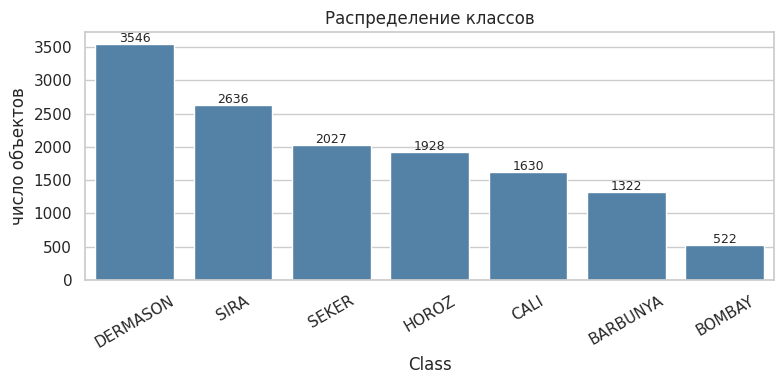

train: (9527, 9) | test (отложенная выборка): (4084, 9)


,mean,std,min,max
Perimeter,855.7557,214.3300,530.6830,1985.3700
MinorAxisLength,202.4123,45.1132,122.5127,460.1985
Extent,0.7498,0.0491,0.5553,0.8584
Solidity,0.9872,0.0046,0.9192,0.9944
roundness,0.8735,0.0591,0.4896,0.9907
Compactness,0.7998,0.0617,0.6406,0.9873
ShapeFactor1,0.0066,0.0011,0.0028,0.0105
ShapeFactor2,0.0017,0.0006,0.0006,0.0037
ShapeFactor4,0.9951,0.0043,0.9477,0.9997


Разброс масштабов (std): в 360454 раз -> нужна стандартизация


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name=SHEET)
if FAST:
    df = train_test_split(df, train_size=2500, stratify=df[TARGET], random_state=RS)[0].reset_index(drop=True)

# --- первичный анализ ---
print("Размер:", df.shape)
print("Пропусков всего:", int(df.isna().sum().sum()), "| полных дубликатов строк:", int(df.duplicated().sum()))
types = pd.DataFrame({"тип": df.dtypes.astype(str), "уникальных": df.nunique()})
print("Типы признаков:", types["тип"].value_counts().to_dict(), "| категориальный столбец только целевой:", TARGET)
cnt = df[TARGET].value_counts(); share = (cnt / len(df) * 100).round(2)
cls = pd.DataFrame({"объектов": cnt, "доля, %": share}); display(cls)
print("Отношение размеров самого большого и самого малого классов: %.2f" % (cnt.max() / cnt.min()))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=cnt.index, y=cnt.values, ax=ax, color="steelblue")
for i, v in enumerate(cnt.values): ax.text(i, v + 30, str(v), ha="center", fontsize=9)
ax.set_title("Распределение классов"); ax.set_ylabel("число объектов"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT}/f_classes.png", dpi=130); plt.show()

# --- признаки: те же 9, что в лабораторной работе 2 (удалены дубли с |r| > 0.95) ---
SELECTED = ["Perimeter", "MinorAxisLength", "Extent", "Solidity", "roundness",
            "Compactness", "ShapeFactor1", "ShapeFactor2", "ShapeFactor4"]
le = LabelEncoder(); y = pd.Series(le.fit_transform(df[TARGET]), index=df.index, name=TARGET)
CLASSES = list(le.classes_); K = len(CLASSES)
X_train, X_test, y_train, y_test = train_test_split(df[SELECTED], y, test_size=0.30, random_state=RS, stratify=y)
print("train:", X_train.shape, "| test (отложенная выборка):", X_test.shape)
scale = X_train.describe().T[["mean", "std", "min", "max"]]; display(scale.round(4))
print("Разброс масштабов (std): в %.0f раз -> нужна стандартизация" % (scale["std"].max() / scale["std"].min()))

### Выводы по данным
- **Структура.** 13611 объектов, 16 числовых признаков и один категориальный столбец – целевой `Class`. Пропусков нет, в наборе есть 68 полностью совпадающих строк (0,5 %), они оставлены без изменений, как в лабораторной работе 2.
- **Баланс классов.** Классы **не сбалансированы**: DERMASON составляет 26,1 % набора, BOMBAY – всего 3,8 %, отношение размеров 6,79. Поэтому (1) разбиения выполняются со **стратификацией**, чтобы доли классов сохранялись в обучающей, проверочных и тестовой частях; (2) наряду с accuracy сообщается macro-F1, не зависящая от размеров классов. Дополнительных мер (взвешивания классов, передискретизации) не применялось: самый малый класс BOMBAY хорошо отделяется по размерным признакам и распознаётся почти безошибочно, а лишние преобразования усложнили бы сравнение с baseline.
- **Кодирование и масштабирование.** Кодировать признаки не нужно (все входные признаки числовые), целевая переменная переводится в целые коды 0–6. Масштабы признаков различаются в 360 тысяч раз (стандартное отклонение от 0,001 до 214), для градиентных методов обучения **необходима стандартизация**. Она выполняется отдельно в каждом фолде по его обучающей части, чтобы данные проверочной части не влияли на преобразование.
- **Признаки.** Использованы те же 9 признаков, что в лабораторной работе 2 (удалены дублирующие признаки с |r| > 0,95), и то же разбиение 70/30 (9527 обучающих и 4084 отложенных объекта).

## 2. Baseline-модель: логистическая регрессия

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)      # одна и та же схема для baseline и нейронных сетей
FOLDS = list(skf.split(X_train, y_train))

base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=RS))
t0 = time.time(); base.fit(X_train, y_train); base_time = time.time() - t0
p_base = base.predict(X_test); proba_base = base.predict_proba(X_test)
base_res = {"accuracy": accuracy_score(y_test, p_base), "macro-F1": f1_score(y_test, p_base, average="macro"),
            "loss (log-loss)": log_loss(y_test, proba_base), "время обучения, с": base_time}
cvb = cross_validate(base, X_train, y_train, cv=skf, scoring={"acc": "accuracy", "f1": "f1_macro"}, return_train_score=True)
base_res.update({"CV accuracy (среднее)": cvb["test_acc"].mean(), "CV accuracy (std)": cvb["test_acc"].std(), "accuracy на train": base.score(X_train, y_train)})
base_tbl = pd.Series(base_res); display(base_tbl.round(4).to_frame("baseline (LogReg)"))
base_tbl.round(5).to_csv(f"{OUT}/baseline.csv")

,baseline (LogReg)
accuracy,0.9292
macro-F1,0.9405
loss (log-loss),0.2066
"время обучения, с",0.1831
CV accuracy (среднее),0.9232
CV accuracy (std),0.0041
accuracy на train,0.9238


### Baseline
Базовой моделью выбрана **логистическая регрессия** (многоклассовая, со стандартизацией признаков в конвейере). Она проста, обучается за доли секунды и задаёт нижнюю границу качества, которую должна превзойти нейронная сеть.

Точность на отложенной выборке **0,9292**, macro-F1 0,9405, потери (log-loss) 0,2066. Средняя точность при 5-кратной кросс-валидации на обучающей части – 0,9232 ± 0,0041; она близка к точности на обучающей выборке (0,9238), то есть логистическая регрессия не переобучается, но и ограничена линейностью границ классов. С этими числами сравниваются все нейронные сети.

## 3. Пятикратная кросс-валидация (корректность разбиения)

In [4]:
# Стратифицированные фолды: доли классов в каждой валидационной части совпадают с исходными
chk = pd.DataFrame({f"fold {k + 1}": y_train.iloc[va].map(dict(enumerate(CLASSES))).value_counts(normalize=True) * 100 for k, (tr, va) in enumerate(FOLDS)})
chk["всё обучающее, %"] = y_train.map(dict(enumerate(CLASSES))).value_counts(normalize=True) * 100
display(chk.round(2))
print("Размеры фолдов (обучение / проверка):", [(len(tr), len(va)) for tr, va in FOLDS])
print("Пересечений train и val в фолдах нет:", all(len(set(tr) & set(va)) == 0 for tr, va in FOLDS),
      "| каждый объект попадает в проверку ровно один раз:", sorted(np.concatenate([va for _, va in FOLDS])) == sorted(range(len(y_train))))
print("Стандартизация обучается внутри каждого фолда только по его обучающей части (утечки нет).")

,fold 1,fold 2,fold 3,fold 4,fold 5,"всё обучающее, %"
Class,,,,,,
DERMASON,26.08,26.08,26.04,26.04,26.04,26.05
SIRA,19.36,19.36,19.37,19.37,19.37,19.37
SEKER,14.90,14.85,14.91,14.91,14.91,14.89
HOROZ,14.17,14.17,14.17,14.17,14.17,14.17
CALI,11.96,12.01,11.97,11.97,11.97,11.98
BARBUNYA,9.71,9.71,9.71,9.71,9.71,9.71
BOMBAY,3.83,3.83,3.83,3.83,3.83,3.83


Размеры фолдов (обучение / проверка): [(7621, 1906), (7621, 1906), (7622, 1905), (7622, 1905), (7622, 1905)]
Пересечений train и val в фолдах нет: True | каждый объект попадает в проверку ровно один раз: True
Стандартизация обучается внутри каждого фолда только по его обучающей части (утечки нет).


### Корректность кросс-валидации
Использована 5-кратная **стратифицированная** кросс-валидация (`StratifiedKFold`, `shuffle=True`, `random_state=44`), одна и та же для baseline и всех нейронных сетей, поэтому конфигурации сравниваются на одинаковых фолдах. Проверки выше показывают: доли классов в каждой проверочной части совпадают с исходными (отличия в десятых долях процента), размеры фолдов равны 7621/1906 и 7622/1905 объектов, обучающая и проверочная части не пересекаются, каждый объект попадает в проверку ровно один раз. Отложенная выборка (4084 объекта) в кросс-валидации не участвует и используется только для финальной оценки.

## 4. Подбор гиперпараметров: Grid Search с кросс-валидацией

### Постановка Grid Search
Перебираются все комбинации двух гиперпараметров (сетка 3 × 3), каждая оценивается 5-кратной кросс-валидацией, всего 45 обучений:
- **скорость обучения** оптимизатора Adam: 10⁻⁴, 10⁻³, 10⁻²;
- **архитектура** (скрытые слои с ReLU, выход softmax на 7 классов): **A** – один слой из 32 нейронов; **B** – два слоя 64–32; **C** – три слоя 128–64–32 с dropout 0,3 после каждого скрытого слоя.

Остальные параметры фиксированы: функция потерь – категориальная кросс-энтропия, размер батча 128, 50 эпох, одинаковая инициализация генератора случайных чисел в каждом фолде. Перебор реализован явными циклами (а не `GridSearchCV`), чтобы для каждого фолда записывать журнал TensorBoard и полную историю обучения. Логи пишутся в `logs_extra/<конфигурация>/fold<номер>/` (подкаталоги `train` и `validation`).

In [5]:
EPOCHS = 3 if FAST else 50
BATCH = 128
LRS = [1e-4, 1e-3, 1e-2]                                   # скорость обучения: 3 значения
ARCHS = {"A": dict(hidden=(32,), dropout=0.0),             # архитектура: 3 варианта
         "B": dict(hidden=(64, 32), dropout=0.0),
         "C": dict(hidden=(128, 64, 32), dropout=0.3)}
CONFIGS = {f"{a}_lr{lr:g}": dict(arch=a, lr=lr, **ARCHS[a]) for a in ARCHS for lr in LRS}
print(pd.DataFrame([{"архитектура": a, "скрытые слои": "-".join(map(str, v["hidden"])), "dropout": v["dropout"]} for a, v in ARCHS.items()]).to_string(index=False))
print("Конфигураций:", len(CONFIGS), "x 5 фолдов =", len(CONFIGS) * 5, "обучений, эпох:", EPOCHS, ", батч:", BATCH)

def make_model(hidden, dropout, lr, n_in):
    m = keras.Sequential([keras.layers.Input((n_in,))])
    for h in hidden:
        m.add(keras.layers.Dense(h, activation="relu"))
        if dropout: m.add(keras.layers.Dropout(dropout))
    m.add(keras.layers.Dense(K, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def run_fold(name, cfg, k):
    """Обучение одной конфигурации на одном фолде; логи TensorBoard: logs_extra/<конфигурация>/fold<k>."""
    def job():
        tr, va = FOLDS[k]
        sc = StandardScaler().fit(X_train.iloc[tr])
        a, b = sc.transform(X_train.iloc[tr]).astype("float32"), sc.transform(X_train.iloc[va]).astype("float32")
        keras.utils.set_random_seed(RS + k)
        m = make_model(cfg["hidden"], cfg["dropout"], cfg["lr"], a.shape[1])
        tb = keras.callbacks.TensorBoard(log_dir=f"{LOGS}/{name}/fold{k + 1}", write_graph=False)
        t0 = time.time()
        h = m.fit(a, y_train.iloc[tr].values, validation_data=(b, y_train.iloc[va].values), epochs=EPOCHS, batch_size=BATCH, verbose=0, callbacks=[tb])
        out = {kk: np.array(v) for kk, v in h.history.items()}; out["time"] = time.time() - t0
        keras.backend.clear_session(); gc.collect()
        return out
    return cached(f"run_{name}_f{k + 1}_{EPOCHS}", job)

RUNS = {}
for name, cfg in CONFIGS.items():
    for k in range(5):
        RUNS[(name, k)] = run_fold(name, cfg, k)
    print(f"{name}: готово, val accuracy по фолдам:", [round(float(RUNS[(name, k)]["val_accuracy"][-1]), 4) for k in range(5)])

архитектура скрытые слои  dropout
          A           32      0.0
          B        64-32      0.0
          C    128-64-32      0.3
Конфигураций: 9 x 5 фолдов = 45 обучений, эпох: 50 , батч: 128


A_lr0.0001: готово, val accuracy по фолдам: [0.8846, 0.8725, 0.8903, 0.8709, 0.9087]


A_lr0.001: готово, val accuracy по фолдам: [0.9276, 0.9244, 0.9223, 0.9312, 0.9302]


A_lr0.01: готово, val accuracy по фолдам: [0.9281, 0.9318, 0.9265, 0.9265, 0.9349]


B_lr0.0001: готово, val accuracy по фолдам: [0.9176, 0.9171, 0.9155, 0.9276, 0.9228]


B_lr0.001: готово, val accuracy по фолдам: [0.9328, 0.9276, 0.9239, 0.9344, 0.9323]


B_lr0.01: готово, val accuracy по фолдам: [0.9244, 0.9224, 0.9213, 0.9228, 0.9291]


C_lr0.0001: готово, val accuracy по фолдам: [0.9171, 0.9182, 0.9139, 0.9265, 0.9192]


C_lr0.001: готово, val accuracy по фолдам: [0.9313, 0.9292, 0.926, 0.9318, 0.9318]


C_lr0.01: готово, val accuracy по фолдам: [0.9255, 0.9244, 0.9202, 0.9265, 0.9307]


## 5. Результаты по фолдам и сравнение конфигураций

In [6]:
rows = []
for (name, k), h in RUNS.items():
    vl = h["val_loss"]; b = int(vl.argmin())
    rows.append({"config": name, "arch": CONFIGS[name]["arch"], "lr": CONFIGS[name]["lr"], "fold": k + 1,
                 "val_acc": h["val_accuracy"][-1], "val_loss": vl[-1], "train_acc": h["accuracy"][-1], "train_loss": h["loss"][-1],
                 "best_epoch": b + 1, "val_loss_min": vl[b], "val_acc_at_best": h["val_accuracy"][b], "time_s": h["time"]})
folds = pd.DataFrame(rows)
folds["gap"] = folds["train_acc"] - folds["val_acc"]                    # разрыв обучение - проверка
folds["loss_rise"] = folds["val_loss"] - folds["val_loss_min"]          # рост потерь после минимума
folds.round(5).to_csv(f"{OUT}/cv_folds.csv", index=False)

agg = folds.groupby("config").agg(arch=("arch", "first"), lr=("lr", "first"),
        val_acc=("val_acc", "mean"), val_acc_std=("val_acc", "std"), val_acc_min=("val_acc", "min"), val_acc_max=("val_acc", "max"),
        val_loss=("val_loss", "mean"), val_loss_std=("val_loss", "std"), train_acc=("train_acc", "mean"), gap=("gap", "mean"),
        best_epoch=("best_epoch", "mean"), val_loss_min=("val_loss_min", "mean"), loss_rise=("loss_rise", "mean"), time_s=("time_s", "mean"))
agg = agg.sort_values("val_acc", ascending=False)
agg.round(5).to_csv(f"{OUT}/cv_summary.csv"); display(agg.round(4))
BEST = agg.index[0]; print("Лучшая конфигурация по средней CV accuracy:", BEST)

,arch,lr,val_acc,val_acc_std,val_acc_min,val_acc_max,val_loss,val_loss_std,train_acc,gap,best_epoch,val_loss_min,loss_rise,time_s
config,,,,,,,,,,,,,,
B_lr0.001,B,0.0010,0.9302,0.0043,0.9239,0.9344,0.1969,0.0117,0.9351,0.0049,49.4,0.1969,0.0000,28.4213
C_lr0.001,C,0.0010,0.9300,0.0025,0.9260,0.9318,0.2012,0.0105,0.9249,-0.0051,40.6,0.1969,0.0043,32.3063
A_lr0.01,A,0.0100,0.9296,0.0037,0.9265,0.9349,0.2032,0.0115,0.9343,0.0047,32.6,0.2006,0.0026,19.6080
A_lr0.001,A,0.0010,0.9272,0.0038,0.9223,0.9312,0.2048,0.0146,0.9287,0.0015,50.0,0.2048,0.0000,17.9173
C_lr0.01,C,0.0100,0.9255,0.0038,0.9202,0.9307,0.2322,0.0234,0.9199,-0.0056,24.8,0.2028,0.0294,33.2541
B_lr0.01,B,0.0100,0.9240,0.0031,0.9213,0.9291,0.2459,0.0274,0.9419,0.0179,12.6,0.2020,0.0439,28.1836
B_lr0.0001,B,0.0001,0.9201,0.0050,0.9155,0.9276,0.2403,0.0134,0.9206,0.0004,50.0,0.2403,0.0000,26.7770
C_lr0.0001,C,0.0001,0.9190,0.0047,0.9139,0.9265,0.2329,0.0149,0.8836,-0.0354,50.0,0.2329,0.0000,31.8382
A_lr0.0001,A,0.0001,0.8854,0.0154,0.8709,0.9087,0.4721,0.0354,0.8845,-0.0009,50.0,0.4721,0.0000,18.7755


Лучшая конфигурация по средней CV accuracy: B_lr0.001


### Сравнение конфигураций
В таблице выше конфигурации упорядочены по средней accuracy на проверочных фолдах (`val_acc`), даны также разброс между фолдами (`val_acc_std` – показатель устойчивости), потери, разрыв между точностью на обучении и проверке (`gap`), эпоха минимальных потерь (`best_epoch`) и время обучения одного фолда.

- **Лучшая по средней точности** – **B_lr0.001** (архитектура 64–32, скорость 10⁻³): 0,9302 ± 0,0043, потери 0,1969, 28 с на фолд.
- **Практически не отличаются от неё** две конфигурации: C_lr0.001 (0,9300 ± 0,0025, самая устойчивая между фолдами, но 32 с) и A_lr0.01 (0,9296 ± 0,0037, самая быстрая из лучших – 20 с). Разница между этими тремя (0,0006) меньше стандартного отклонения по фолдам, поэтому статистически они неразличимы.
- **Худшая** – A_lr0.0001 (0,8854 ± 0,0154): маленькая сеть с очень малой скоростью обучения за 50 эпох практически не обучается, и результат сильно зависит от фолда.
- **Время обучения** определяется размером сети: около 18 с у архитектуры A, 28 с у B и 32 с у C (на скорость обучения оно не зависит).

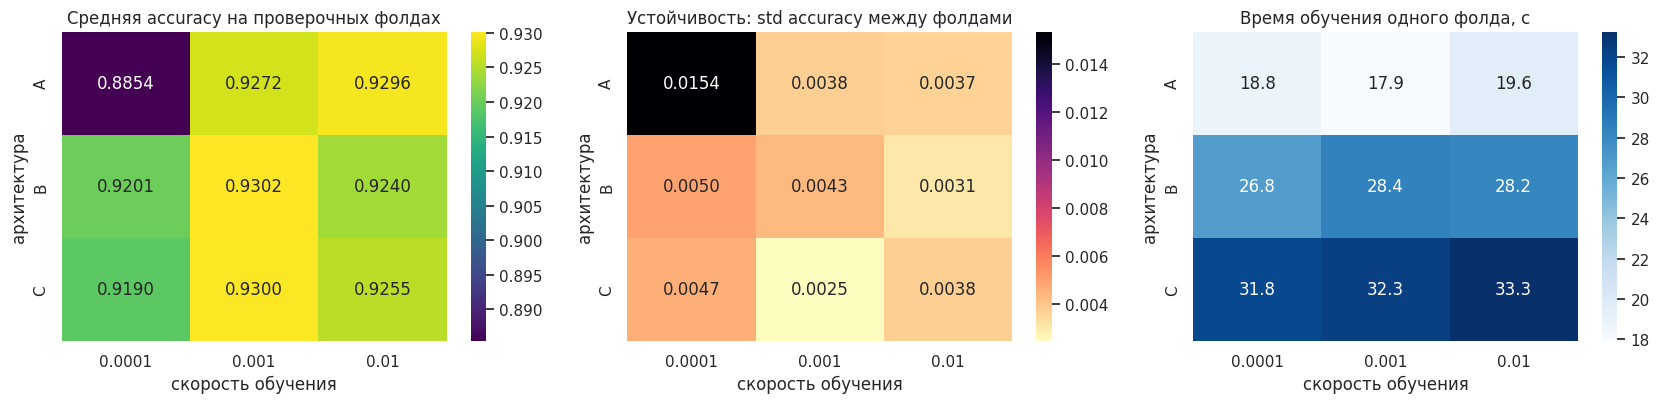

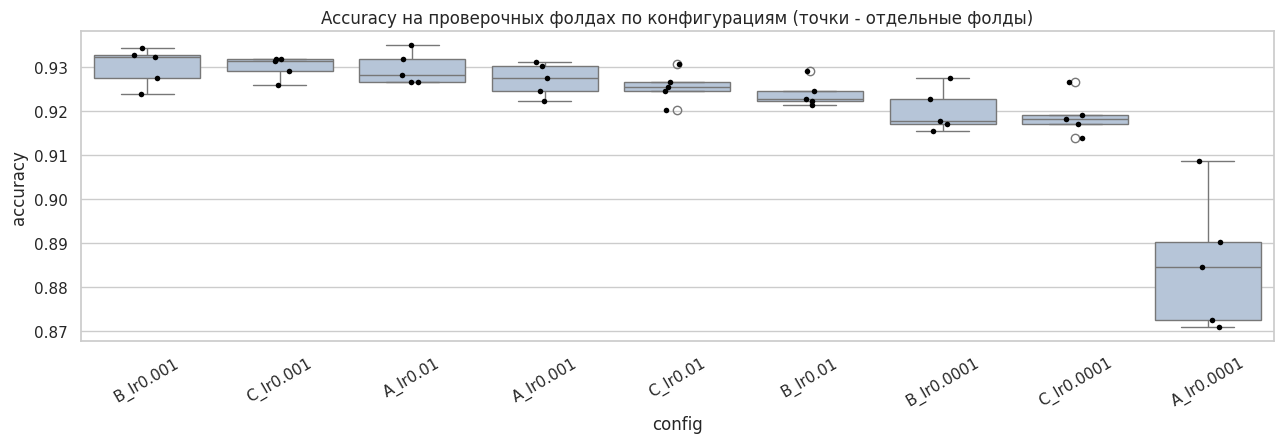

In [7]:
# Тепловые карты: средняя CV accuracy, её разброс по фолдам и время обучения
pv = lambda col: agg.pivot(index="arch", columns="lr", values=col)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.heatmap(pv("val_acc"), annot=True, fmt=".4f", cmap="viridis", ax=axes[0]); axes[0].set_title("Средняя accuracy на проверочных фолдах")
sns.heatmap(pv("val_acc_std"), annot=True, fmt=".4f", cmap="magma_r", ax=axes[1]); axes[1].set_title("Устойчивость: std accuracy между фолдами")
sns.heatmap(pv("time_s"), annot=True, fmt=".1f", cmap="Blues", ax=axes[2]); axes[2].set_title("Время обучения одного фолда, с")
for ax in axes: ax.set_xlabel("скорость обучения"); ax.set_ylabel("архитектура")
plt.tight_layout(); plt.savefig(f"{OUT}/f_heatmaps.png", dpi=130); plt.show()

# Разброс точности по фолдам для каждой конфигурации
order = list(agg.index)
fig, ax = plt.subplots(figsize=(13, 4.6))
sns.boxplot(data=folds, x="config", y="val_acc", order=order, color="lightsteelblue", ax=ax)
sns.stripplot(data=folds, x="config", y="val_acc", order=order, color="black", size=4, ax=ax)
ax.set_title("Accuracy на проверочных фолдах по конфигурациям (точки - отдельные фолды)"); ax.tick_params(axis="x", rotation=30); ax.set_ylabel("accuracy")
plt.tight_layout(); plt.savefig(f"{OUT}/f_fold_boxplot.png", dpi=130); plt.show()

### Устойчивость и разброс по фолдам
На тепловых картах видно, как качество зависит от пары (архитектура, скорость обучения): светлая область (выше точность) расположена в столбцах 10⁻³ и 10⁻², самые тёмные ячейки – при 10⁻⁴. Тепловая карта разброса и ящичковая диаграмма показывают, что устойчивость между фолдами у хороших конфигураций близка (стандартное отклонение 0,0025–0,0043), а у конфигураций с 10⁻⁴ она хуже (стандартное отклонение по всем запускам с данной скоростью 0,0189 против 0,0036 при 10⁻³) – сеть ещё не вышла на плато, и результат зависит от конкретного фолда.

## 6. Мониторинг обучения: кривые и TensorBoard

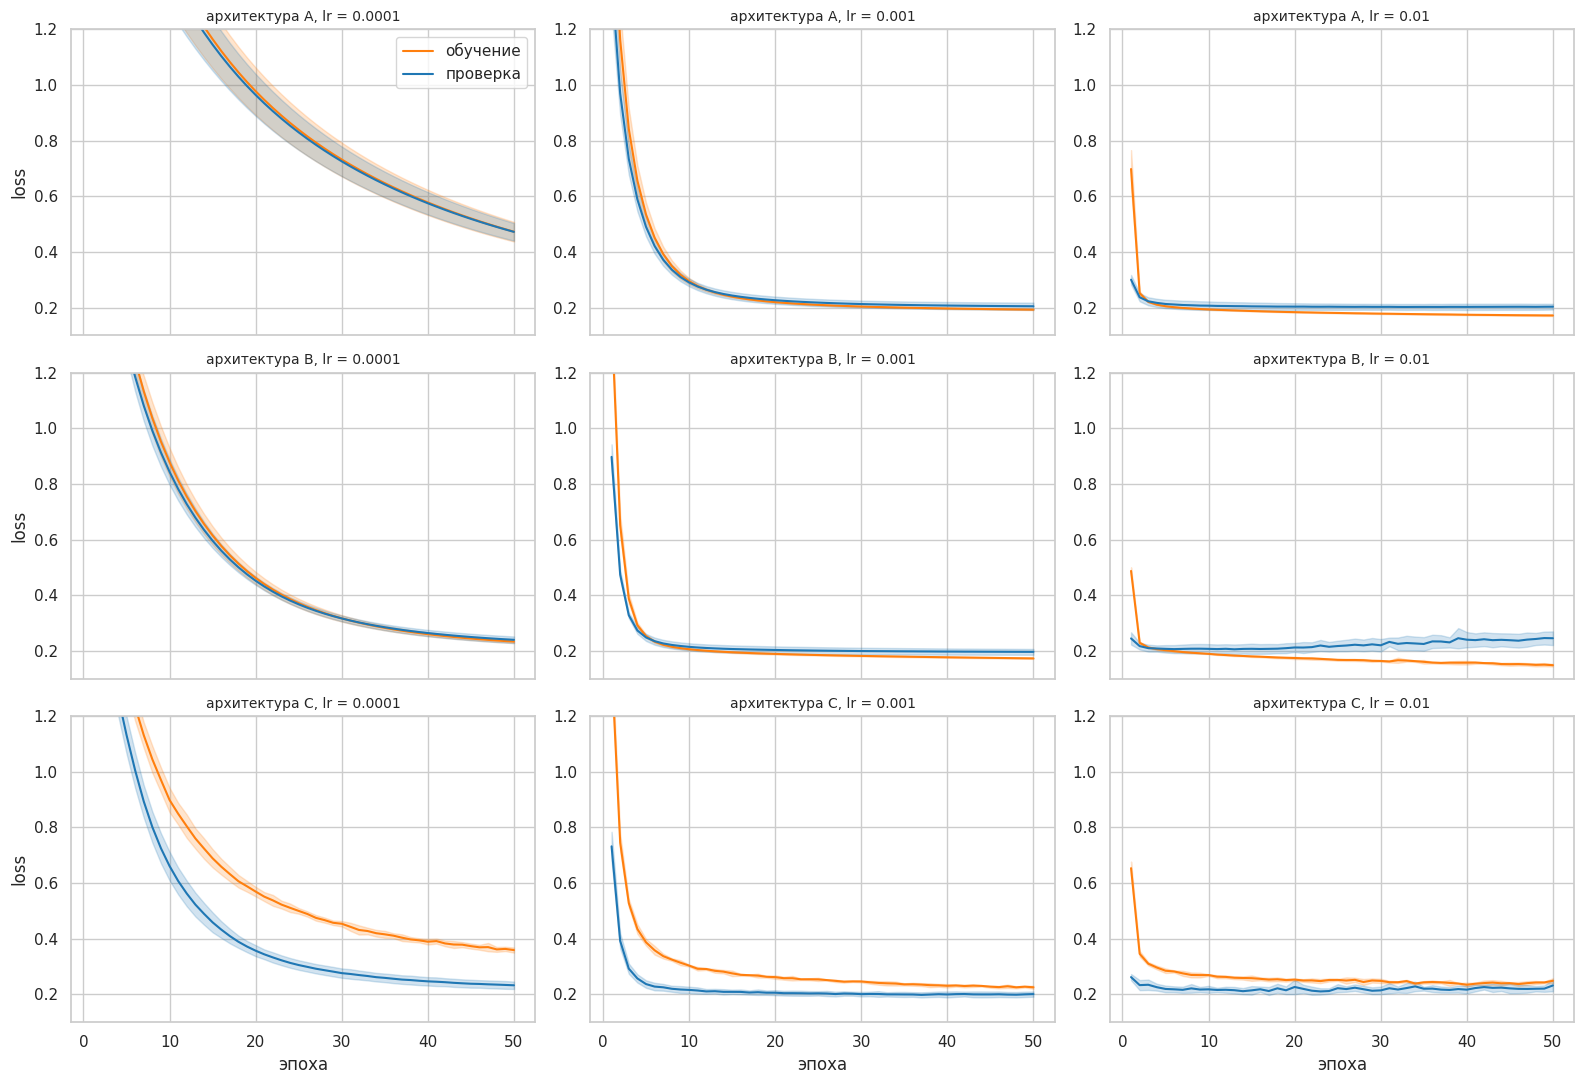

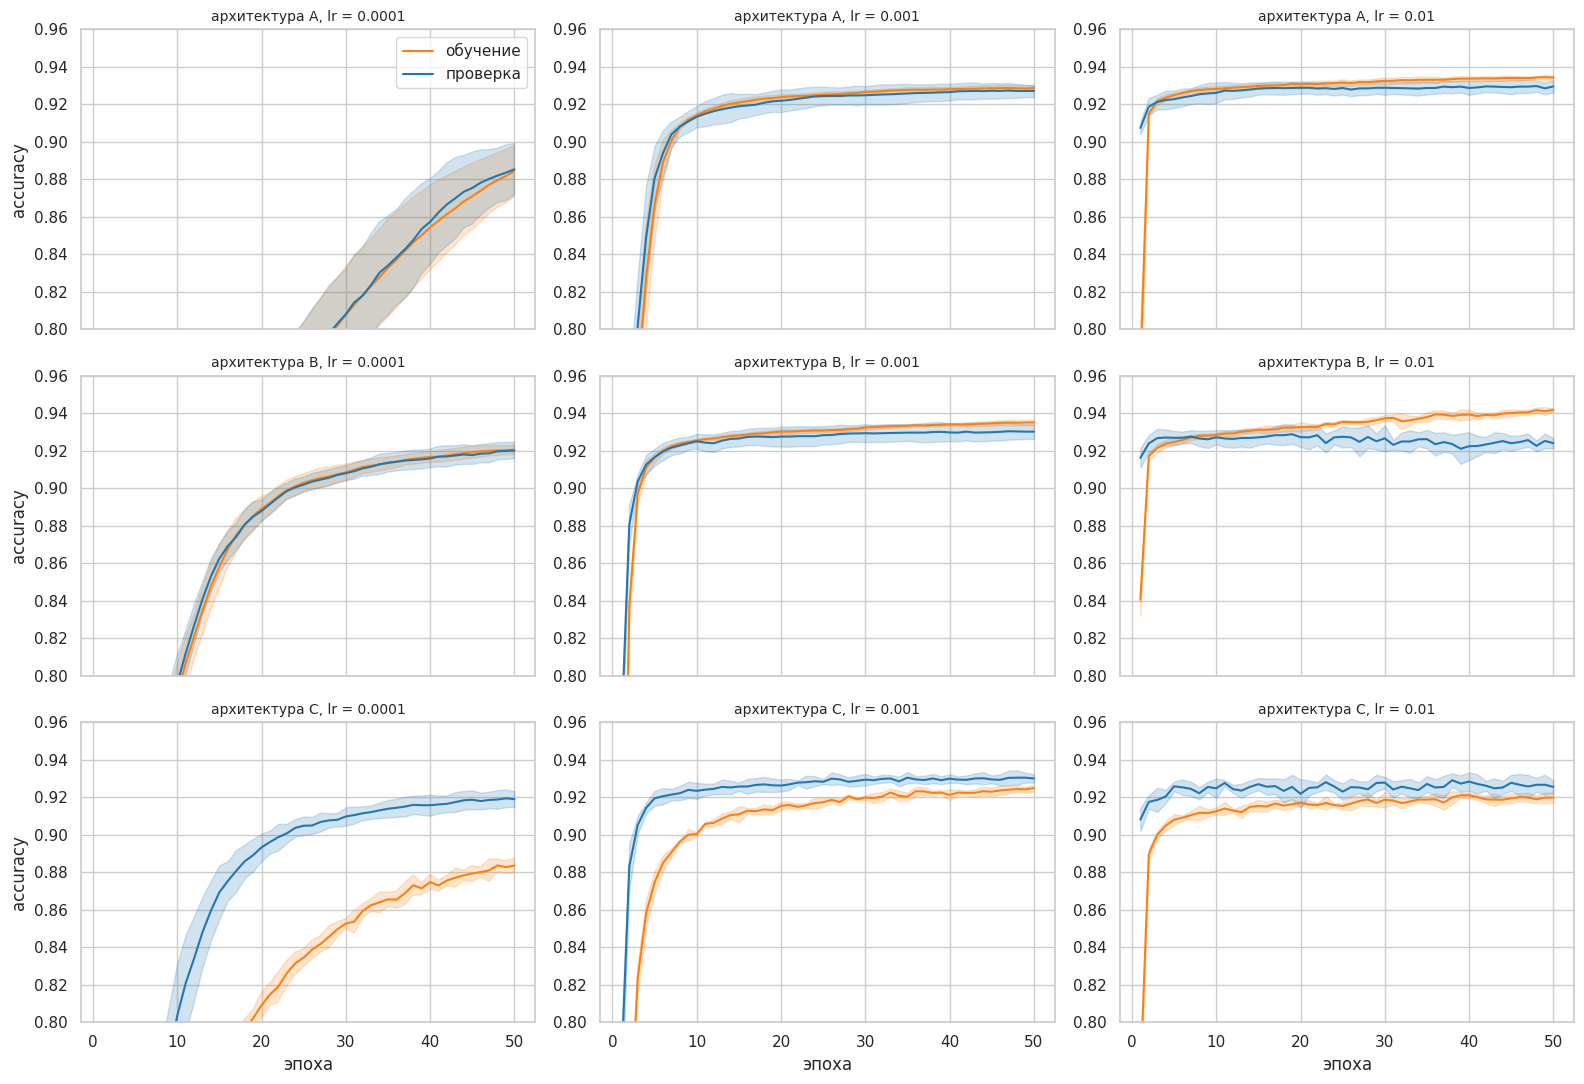

In [8]:
# Кривые обучения всех конфигураций (среднее по 5 фолдам; полоса - разброс между фолдами)
def curves(key_tr, key_va, ylabel, fname, ylim=None):
    fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True)
    for i, a in enumerate(ARCHS):
        for j, lr in enumerate(LRS):
            ax = axes[i, j]; name = f"{a}_lr{lr:g}"
            for key, lab, col in [(key_tr, "обучение", "tab:orange"), (key_va, "проверка", "tab:blue")]:
                arr = np.array([RUNS[(name, k)][key] for k in range(5)]); m_, s_ = arr.mean(0), arr.std(0); x = np.arange(1, arr.shape[1] + 1)
                ax.plot(x, m_, color=col, label=lab); ax.fill_between(x, m_ - s_, m_ + s_, color=col, alpha=0.2)
            if ylim: ax.set_ylim(*ylim)
            ax.set_title(f"архитектура {a}, lr = {lr:g}", fontsize=10)
            if j == 0: ax.set_ylabel(ylabel)
            if i == 2: ax.set_xlabel("эпоха")
            if i == 0 and j == 0: ax.legend()
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=120); plt.show()
curves("loss", "val_loss", "loss", "f_curves_loss.png", ylim=(0.1, 1.2))
curves("accuracy", "val_accuracy", "accuracy", "f_curves_acc.png", ylim=(0.8, 0.96))

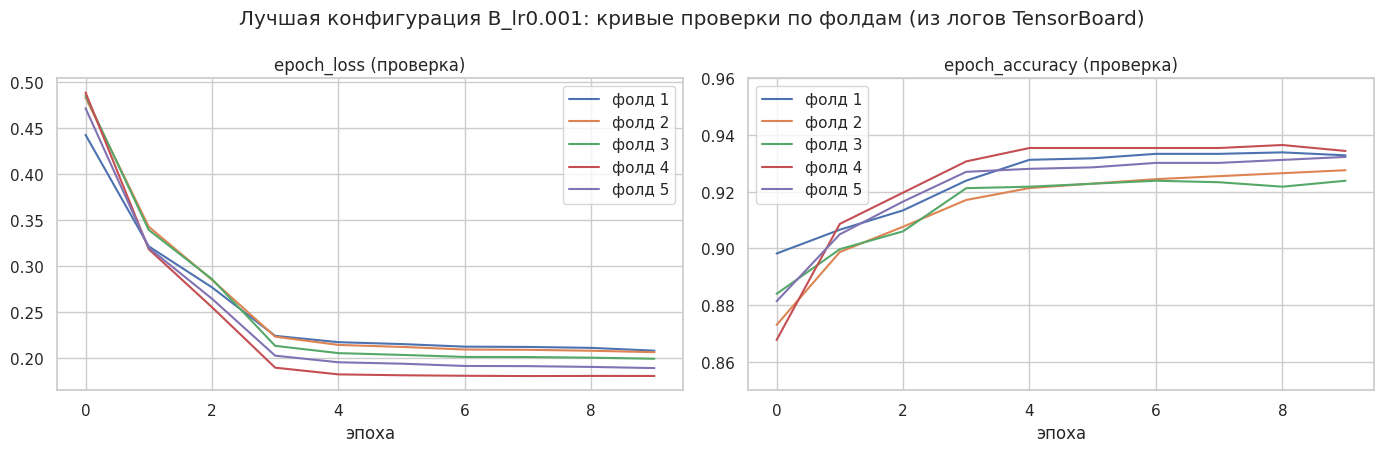

Структура логов: logs_extra/<конфигурация>/fold<1..5>/{train,validation}


In [9]:
# Кривые лучшей конфигурации на каждом фолде, прочитанные из логов TensorBoard (то, что показывает вкладка Scalars)
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
def read_tb(logdir):
    out = {}
    for sub in ["train", "validation"]:
        ea = EventAccumulator(f"{logdir}/{sub}"); ea.Reload()
        out[sub] = {t: np.array([float(tf.make_ndarray(e.tensor_proto)) for e in ea.Tensors(t)]) for t in ea.Tags()["tensors"]}
    return out
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for k in range(5):
    tb = read_tb(f"{LOGS}/{BEST}/fold{k + 1}")
    axes[0].plot(tb["validation"]["epoch_loss"], label=f"фолд {k + 1}"); axes[1].plot(tb["validation"]["epoch_accuracy"], label=f"фолд {k + 1}")
axes[0].set_title("epoch_loss (проверка)"); axes[1].set_title("epoch_accuracy (проверка)"); axes[1].set_ylim(0.85, 0.96)
for ax in axes: ax.set_xlabel("эпоха"); ax.legend()
plt.suptitle(f"Лучшая конфигурация {BEST}: кривые проверки по фолдам (из логов TensorBoard)")
plt.tight_layout(); plt.savefig(f"{OUT}/f_best_folds.png", dpi=130); plt.show()
print("Структура логов:", f"{LOGS}/<конфигурация>/fold<1..5>/{{train,validation}}")

### Мониторинг обучения и TensorBoard
Кривые обучения всех девяти конфигураций показаны на графиках потерь и точности (среднее по 5 фолдам и разброс между ними); отдельно показаны кривые проверки лучшей конфигурации на каждом из пяти фолдов, прочитанные из файлов журнала TensorBoard.

**Что видно на кривых.**
- При скорости **10⁻⁴** потери и на обучении, и на проверке продолжают снижаться до конца 50 эпох: сеть **недообучена**, обучения не хватает по числу эпох (особенно у небольшой сети A).
- При **10⁻³** кривые сходятся плавно, к 40–50 эпохе выходят на плато; кривые проверки и обучения близки.
- При **10⁻²** обучение быстрое, но шумное: у архитектуры B потери на проверке достигают минимума около 13-й эпохи и затем растут при продолжающемся снижении потерь на обучении – **переобучение**. Dropout (архитектура C) смягчает рост потерь, но точность на обучении при этом ниже, чем на проверке (dropout действует только при обучении).
- Кривые по фолдам лучшей конфигурации идут рядом: поведение сети от разбиения почти не зависит.

**Просмотр логов в TensorBoard.** Структура: `logs_extra/<конфигурация>/fold<1..5>/{train,validation}`, финальные обучения – `logs_extra/final/seed<0..4>`. Запуск в терминале (из папки с ноутбуком, в активированном окружении):

```
tensorboard --logdir logs_extra
```

Затем откройте `http://localhost:6006`. На вкладке **Scalars** доступны `epoch_loss` и `epoch_accuracy` для обучающей (`train`) и проверочной (`validation`) частей. Слева в поле Runs можно отфильтровать запуски регулярным выражением: например, `B_lr0.001` покажет пять фолдов одной конфигурации, а `lr0.01` – сравнение трёх архитектур при скорости 10⁻². В ноутбуке (Jupyter) то же можно вывести ячейкой: `%load_ext tensorboard` и `%tensorboard --logdir logs_extra`; в VS Code – командой *Python: Launch TensorBoard*.

## 7. Влияние гиперпараметров и признаки переобучения

In [10]:
# Средние по факторам и доля вариации точности, объясняемая каждым гиперпараметром (двухфакторный дисперсионный анализ, сбалансированный план 3x3x5)
by_lr = folds.groupby("lr")["val_acc"].agg(["mean", "std"]); by_arch = folds.groupby("arch")["val_acc"].agg(["mean", "std"])
display(by_lr.round(4)); display(by_arch.round(4))
g = folds["val_acc"].mean(); n_f = 5
ss_tot = ((folds["val_acc"] - g) ** 2).sum()
ss_lr = len(ARCHS) * n_f * ((by_lr["mean"] - g) ** 2).sum()
ss_ar = len(LRS) * n_f * ((by_arch["mean"] - g) ** 2).sum()
cell = folds.groupby(["arch", "lr"])["val_acc"].mean()
ss_cells = n_f * ((cell - g) ** 2).sum()
ss_int = ss_cells - ss_lr - ss_ar; ss_err = ss_tot - ss_cells
eff = pd.Series({"скорость обучения": ss_lr, "архитектура": ss_ar, "взаимодействие": ss_int, "случайность (фолды)": ss_err}) / ss_tot * 100
display(eff.round(1).to_frame("доля вариации accuracy, %"))
eff.round(2).to_csv(f"{OUT}/effects.csv")

# Признаки недообучения и переобучения по конфигурациям
def diagnose(r):
    if r["best_epoch"] >= EPOCHS - 2 and r["val_acc"] < agg["val_acc"].max() - 0.003: return "недообучение: не сошлась за %d эпох" % EPOCHS
    if r["loss_rise"] > 0.03 and r["best_epoch"] < EPOCHS - 10: return "переобучение: потери растут после эпохи %d" % round(r["best_epoch"])
    return "нет выраженных признаков"
diag = agg[["train_acc", "val_acc", "gap", "best_epoch", "val_loss_min", "val_loss", "loss_rise"]].copy(); diag["вывод"] = agg.apply(diagnose, axis=1)
display(diag.round(4)); diag.round(5).to_csv(f"{OUT}/diagnosis.csv")

,mean,std
lr,,
0.0001,0.9082,0.0189
0.0010,0.9291,0.0036
0.0100,0.9263,0.0041


,mean,std
arch,,
A,0.9140,0.0227
B,0.9248,0.0058
C,0.9248,0.0058


,"доля вариации accuracy, %"
скорость обучения,41.7
архитектура,12.4
взаимодействие,30.5
случайность (фолды),15.4


,train_acc,val_acc,gap,best_epoch,val_loss_min,val_loss,loss_rise,вывод
config,,,,,,,,
B_lr0.001,0.9351,0.9302,0.0049,49.4,0.1969,0.1969,0.0000,нет выраженных признаков
C_lr0.001,0.9249,0.9300,-0.0051,40.6,0.1969,0.2012,0.0043,нет выраженных признаков
A_lr0.01,0.9343,0.9296,0.0047,32.6,0.2006,0.2032,0.0026,нет выраженных признаков
A_lr0.001,0.9287,0.9272,0.0015,50.0,0.2048,0.2048,0.0000,недообучение: не сошлась за 50 эпох
C_lr0.01,0.9199,0.9255,-0.0056,24.8,0.2028,0.2322,0.0294,нет выраженных признаков
B_lr0.01,0.9419,0.9240,0.0179,12.6,0.2020,0.2459,0.0439,переобучение: потери растут после эпохи 13
B_lr0.0001,0.9206,0.9201,0.0004,50.0,0.2403,0.2403,0.0000,недообучение: не сошлась за 50 эпох
C_lr0.0001,0.8836,0.9190,-0.0354,50.0,0.2329,0.2329,0.0000,недообучение: не сошлась за 50 эпох
A_lr0.0001,0.8845,0.8854,-0.0009,50.0,0.4721,0.4721,0.0000,недообучение: не сошлась за 50 эпох


### Влияние гиперпараметров
Средняя точность по значениям скорости обучения: 10⁻⁴ – 0,9082, 10⁻³ – 0,9291, 10⁻² – 0,9263; по архитектурам: A – 0,9140, B – 0,9248, C – 0,9248. Разложение вариации точности между 45 обучениями (двухфакторный дисперсионный анализ, описательный) показывает: на **скорость обучения** приходится 41,7 %, на **архитектуру** – 12,4 %, на **их взаимодействие** – 30,5 %, на случайность между фолдами – 15,4 %. Фолды строятся на одних данных и не вполне независимы, поэтому цифры стоит читать как оценку порядка величин, а не как строгие доли.

**Вывод.** Сильнее всего на качество повлияла **скорость обучения**, причём главным образом из-за слишком малого значения 10⁻⁴ (недообучение за 50 эпох). Архитектура сама по себе влияет слабее: средние для B и C одинаковы, A отстаёт из-за провала при 10⁻⁴. Заметное **взаимодействие** объясняется тем, что оптимальная скорость зависит от размера сети: маленькой сети A нужна большая скорость (лучшая A при 10⁻², 0,9296), а сетям B и C при 10⁻² она вредит (переобучение и шум: 0,9240 и 0,9255). Заметим, что архитектура C отличается от B сразу тремя признаками (ещё один слой, больше нейронов, dropout), поэтому вклад dropout отдельно из этого эксперимента выделить нельзя; по косвенным признакам (меньший рост потерь при 10⁻²: 0,0294 против 0,0439, меньший разброс по фолдам при 10⁻³) он действует как регуляризация.

**Недообучение и переобучение** (таблица выше: `gap` – разрыв точности обучение – проверка, `loss_rise` – рост потерь на проверке после минимума):
- **недообучение** при 10⁻⁴ у всех архитектур и у A при 10⁻³: эпоха минимума потерь – последняя, потери ещё снижаются; у A при 10⁻⁴ точность низка и на обучении (0,8845), и на проверке (0,8854);
- **переобучение** у B при 10⁻²: точность на обучении 0,9419 против 0,9240 на проверке (разрыв 0,0179), потери на проверке выросли после минимума на 0,0439; умеренно – у C при 10⁻²;
- лучшие конфигурации (B и C при 10⁻³) выраженных признаков ни того, ни другого не имеют: разрыв около нуля, потери на проверке выходят на плато.

## 8. Финальная оценка лучшей модели и сравнение с baseline

Лучшая конфигурация: B_lr0.001 {'arch': 'B', 'lr': 0.001, 'hidden': (64, 32), 'dropout': 0.0} | эпох при финальном обучении: 49


,accuracy,macro-F1,loss,accuracy на train,"время обучения, с"
0,0.9373,0.9470,0.1786,0.9359,29.9072
1,0.9371,0.9467,0.1798,0.9373,30.8665
2,0.9322,0.9429,0.1827,0.9388,29.7281
3,0.9349,0.9455,0.1811,0.9357,30.8756
4,0.9354,0.9455,0.1856,0.9357,30.6218


,baseline (LogReg),нейронная сеть B_lr0.001 (среднее),"нейронная сеть, std"
accuracy,0.9292,0.9354,0.0021
macro-F1,0.9405,0.9455,0.0016
loss,0.2066,0.1816,0.0028
accuracy на train,0.9238,0.9367,0.0014
"время обучения, с",0.1831,30.3998,0.5448


Сеть верна, baseline ошибся: 66; наоборот: 33; тест Макнемара p = 0.00119
Прирост accuracy относительно baseline: 0.0061 (стандартная ошибка accuracy на 4084 объектах: 0.0038)


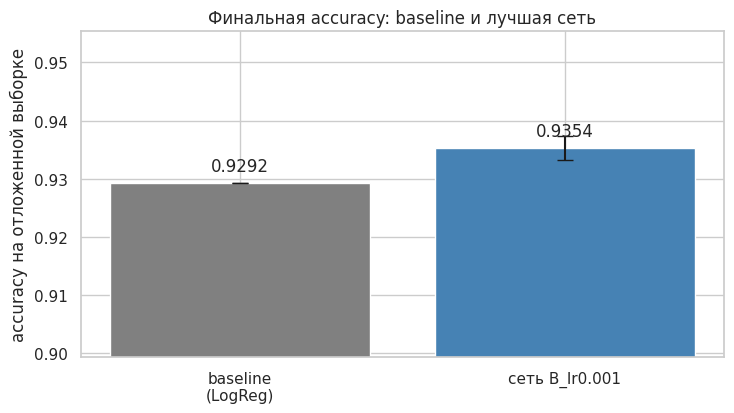

In [11]:
BEST_CFG = CONFIGS[BEST]; EP_FINAL = int(np.clip(round(agg.loc[BEST, "best_epoch"]), 10, EPOCHS))
print("Лучшая конфигурация:", BEST, BEST_CFG, "| эпох при финальном обучении:", EP_FINAL)

def final_nn():
    sc = StandardScaler().fit(X_train)
    a, b = sc.transform(X_train).astype("float32"), sc.transform(X_test).astype("float32")
    res, probas, hists = [], [], []
    for s in range(2 if FAST else 5):
        keras.utils.set_random_seed(RS + 100 + s)
        m = make_model(BEST_CFG["hidden"], BEST_CFG["dropout"], BEST_CFG["lr"], a.shape[1])
        tb = keras.callbacks.TensorBoard(log_dir=f"{LOGS}/final/seed{s}", write_graph=False)
        t0 = time.time(); h = m.fit(a, y_train.values, validation_data=(b, y_test.values), epochs=EP_FINAL, batch_size=BATCH, verbose=0, callbacks=[tb]); dt = time.time() - t0
        pr = m.predict(b, verbose=0); pd_ = pr.argmax(1)
        res.append({"accuracy": accuracy_score(y_test, pd_), "macro-F1": f1_score(y_test, pd_, average="macro"), "loss": log_loss(y_test, pr),
                    "accuracy на train": accuracy_score(y_train, m.predict(a, verbose=0).argmax(1)), "время обучения, с": dt})
        probas.append(pr); hists.append({kk: np.array(v) for kk, v in h.history.items()})
        keras.backend.clear_session(); gc.collect()
    return pd.DataFrame(res), probas, hists
fin_runs, fin_probas, fin_hists = cached(f"final_{BEST}_{EP_FINAL}", final_nn)
display(fin_runs.round(4))

fin = pd.DataFrame({"baseline (LogReg)": {"accuracy": base_res["accuracy"], "macro-F1": base_res["macro-F1"], "loss": base_res["loss (log-loss)"], "accuracy на train": base_res["accuracy на train"], "время обучения, с": base_res["время обучения, с"]},
                    f"нейронная сеть {BEST} (среднее)": fin_runs.mean(), "нейронная сеть, std": fin_runs.std()})
display(fin.round(4)); fin.round(5).to_csv(f"{OUT}/final_vs_baseline.csv")

# значимость различия: точный тест Макнемара на отложенной выборке (первый запуск сети против baseline)
ok_n = fin_probas[0].argmax(1) == y_test.values; ok_b = p_base == y_test.values
b_, c_ = int((ok_n & ~ok_b).sum()), int((~ok_n & ok_b).sum())
p = binomtest(b_, b_ + c_, 0.5).pvalue if b_ + c_ else 1.0
print(f"Сеть верна, baseline ошибся: {b_}; наоборот: {c_}; тест Макнемара p = {p:.3g}")
se = np.sqrt(fin_runs["accuracy"].mean() * (1 - fin_runs["accuracy"].mean()) / len(y_test))
print("Прирост accuracy относительно baseline: %.4f (стандартная ошибка accuracy на %d объектах: %.4f)" % (fin_runs["accuracy"].mean() - base_res["accuracy"], len(y_test), se))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
labels = ["baseline\n(LogReg)", f"сеть {BEST}"]; vals = [base_res["accuracy"], fin_runs["accuracy"].mean()]
ax.bar(labels, vals, yerr=[0, fin_runs["accuracy"].std()], capsize=6, color=["gray", "steelblue"])
for i, v in enumerate(vals): ax.text(i, v + 0.002, f"{v:.4f}", ha="center")
ax.set_ylim(min(vals) - 0.03, max(vals) + 0.02); ax.set_ylabel("accuracy на отложенной выборке"); ax.set_title("Финальная accuracy: baseline и лучшая сеть")
plt.tight_layout(); plt.savefig(f"{OUT}/f_final.png", dpi=130); plt.show()

### Финальная оценка и сравнение с baseline
Лучшая конфигурация **B_lr0.001** переобучена на всём обучающем подмножестве (9527 объектов) в течение 49 эпох (среднее число эпох до минимума потерь по фолдам); обучение повторено 5 раз с разной инициализацией, отложенная выборка использована один раз.

| Показатель | baseline (LogReg) | Нейронная сеть B_lr0.001 (среднее ± std по 5 запускам) |
|---|---|---|
| accuracy | 0,9292 | **0,9354** ± 0,0021 |
| macro-F1 | 0,9405 | **0,9455** ± 0,0016 |
| потери (log-loss) | 0,2066 | **0,1815** ± 0,0027 |
| accuracy на обучающей выборке | 0,9238 | 0,9367 |
| время обучения, с | 0,18 | 30,4 |

- Нейронная сеть превосходит baseline на **0,61 п. п.** по точности, на 0,50 п. п. по macro-F1 и снижает потери на 12 %. Точный тест Макнемара на отложенной выборке (66 объектов, верно классифицированных только сетью, против 33 – только baseline) даёт p ≈ 0,001: различие значимо. Стандартная ошибка accuracy на 4084 объектах около 0,4 п. п., так что прирост невелик по абсолютной величине и сопоставим с ней; существенной разницы в качестве между линейным и нелинейным классификатором на этих признаках нет.
- Цена прироста: обучение занимает около 30 секунд против долей секунды у логистической регрессии.
- Признаков переобучения у итоговой сети нет: точность на обучении (0,9367) почти равна точности на тесте (0,9354), разброс между запусками мал.

In [12]:
# Эффект настройки: все конфигурации против baseline по средней CV accuracy
cmp_ = agg[["val_acc", "val_acc_std", "val_loss", "time_s"]].copy()
cmp_.loc["baseline (LogReg)"] = [cvb["test_acc"].mean(), cvb["test_acc"].std(), np.nan, base_time]
cmp_["прирост к baseline"] = cmp_["val_acc"] - cvb["test_acc"].mean()
display(cmp_.sort_values("val_acc", ascending=False).round(4)); cmp_.round(5).to_csv(f"{OUT}/cv_vs_baseline.csv")

,val_acc,val_acc_std,val_loss,time_s,прирост к baseline
config,,,,,
B_lr0.001,0.9302,0.0043,0.1969,28.4213,0.0070
C_lr0.001,0.9300,0.0025,0.2012,32.3063,0.0068
A_lr0.01,0.9296,0.0037,0.2032,19.6080,0.0064
A_lr0.001,0.9272,0.0038,0.2048,17.9173,0.0040
C_lr0.01,0.9255,0.0038,0.2322,33.2541,0.0023
B_lr0.01,0.9240,0.0031,0.2459,28.1836,0.0008
baseline (LogReg),0.9232,0.0041,NaN,0.1831,0.0000
B_lr0.0001,0.9201,0.0050,0.2403,26.7770,-0.0030
C_lr0.0001,0.9190,0.0047,0.2329,31.8382,-0.0042


## 9. Итоговый вывод
1. **Данные.** Классы не сбалансированы (отношение 6,79), поэтому применены стратификация и macro-F1; признаки имеют масштабы, отличающиеся в 360 тысяч раз, поэтому выполнена стандартизация внутри каждого фолда.
2. **Baseline.** Логистическая регрессия: точность 0,9292 на отложенной выборке и 0,9232 ± 0,0041 при кросс-валидации.
3. **Лучшая конфигурация.** По Grid Search (3 скорости × 3 архитектуры × 5 фолдов) лучшей оказалась **архитектура 64–32 со скоростью обучения 10⁻³**: 0,9302 ± 0,0043, потери 0,1969. Выбор обоснован наибольшей средней точностью, выходом потерь на плато без признаков переобучения и средним временем обучения. Две конфигурации (C при 10⁻³ и A при 10⁻²) статистически неотличимы по точности: C устойчивее между фолдами, A быстрее почти на треть.
4. **Эффект настройки.** Сильнее всего на результат повлияла скорость обучения (10⁻⁴ даёт недообучение), затем – её взаимодействие с размером сети; сама архитектура влияет слабее. Ненастроенная конфигурация могла бы дать от 0,8854 до 0,9302, то есть настройка важна главным образом для того, чтобы не попасть в плохие значения.
5. **Финал.** Лучшая сеть даёт 0,9354 против 0,9292 у baseline (+0,61 п. п., значимо по тесту Макнемара), macro-F1 0,9455 против 0,9405, ценой роста времени обучения примерно в 160 раз.
6. **Ограничения.** Число эпох фиксировано (50): при 10⁻⁴ обучение не завершено, и более длительное обучение могло бы изменить ранжирование; перебирались только три значения каждого гиперпараметра, а архитектуры отличались сразу несколькими признаками; прирост относительно baseline невелик (около 0,6 п. п.), а оценка получена на одном разбиении.